# Forecasting Heating Demand

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [5]:
data = pd.read_csv("buildings_data.csv")

In [6]:
data

,time_point,heating_power
0,1,2520.671379
1,2,2125.228985
2,3,1950.870059
3,4,2537.853104
4,5,2884.229005
...,...,...
2135,2136,1605.379691
2136,2137,1493.435626
2137,2138,1207.299981
2138,2139,1608.077281


Text(0.5, 0, 'Week')

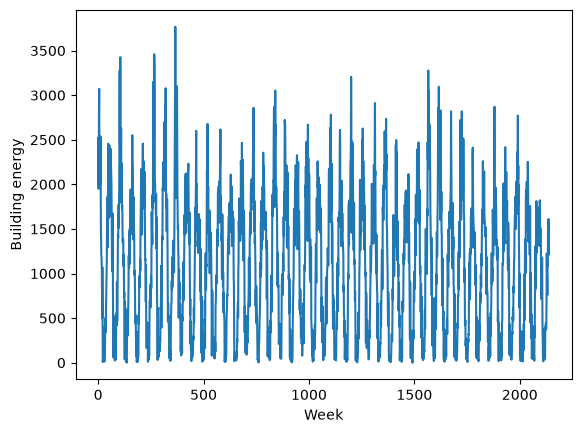

In [7]:
plt.plot(data.heating_power)
plt.ylabel("Building energy")
plt.xlabel("Week")

# Splitting of data and properly aligning training data



In [32]:
W = 24
H = 20

train, test = data.heating_power[:-H], data.heating_power[-H:] # Forecast the last 12 weeks in the series

In [33]:
def create_supervised(input_seq, W, H):
    """
    The function transform a time series into a supervised setting where the model
    has input data (X) and the output data (y). At each time point both / row in the matrices
    the length of the input & output sequence may be > 0.

    Arguments:
    input_seq : The time series data that needs to be transformed into a supervised setting
    W : Length of the input sequence (window) W > 0
    H : Length of the forecast horizon H > 0
    """
    X = np.zeros(W)
    y = np.zeros(H)
    i = 0
    while True:
        res_X = input_seq[i:W+i]
        X = np.vstack([X, res_X])
        res_y = input_seq[(W+i) : (W+i) + H]
        if len(res_y) != H:
            break
        y = np.vstack([y, res_y])
        i += 1

    X = X[1:-1, :]
    y = y[1:, ]
    return X,y

In [34]:
X_train, y_train = create_supervised(train, W = W, H = H)

In [11]:
X_train[1,:]

array([2125.22898465, 1950.87005898, 2537.85310422, 2884.22900541,
       3070.67687149, 2055.87523138, 2524.35648199, 2255.79789159,
       2091.84938015, 2000.43597291, 2537.89266262, 2029.16427017,
       1515.66052217, 1301.18115931, 1197.8818167 , 1189.46449331,
       1094.47892102,  915.55122429,  499.02452418, 1070.78060149,
        574.47778563,    7.41980635,   44.02953408,  160.913808  ])

In [ ]:
y_train.shape

Example predictions obtained from a neural network model; this is only included to have some data available for a plot:

In [13]:
predictions = np.array([[ 859.06741002,  987.751046  , 1076.4043119 , 1267.18763558,
        1259.22625598, 1299.50373814, 1349.2911868 , 1531.86286671,
        1577.16321693, 1678.94887763, 1750.88112554, 1722.47152106]])

In [ ]:
# MLP
#model = MLPRegressor()
#model.fit(X_train,y_train)
#x_new = train.values[-24:].reshape(1, -1) 
#predictions = model.predict(x_new / 1000) * 1000 

/Users/anton/Documents/skol/Ai/TDDE56-Project/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


MAE kNN: 222.2252356712852


Text(0, 0.5, 'Building energy (kW)')

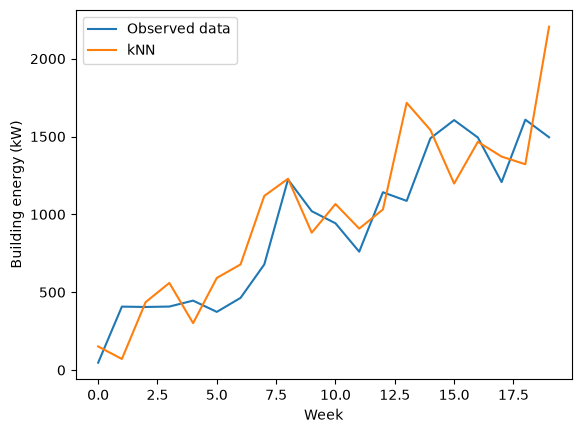

In [ ]:
#kNN
from sklearn.neighbors import KNeighborsRegressor

k = 1
knn_model = KNeighborsRegressor(n_neighbors=k)
knn_model.fit(X_train, y_train)                 

x_knn = train.values[-W:].reshape(1, -1)       # senaste veckorna
predictions_knn = knn_model.predict(x_knn)     

print("MAE kNN:", mean_absolute_error(test.values, predictions_knn.flatten()))

plt.plot(test.values, label="Observed data")
plt.plot(predictions_knn.flatten(), label="kNN")
plt.legend()
plt.xlabel("Week")
plt.ylabel("Building energy (kW)")

Text(0, 0.5, 'Building energy (kW)')

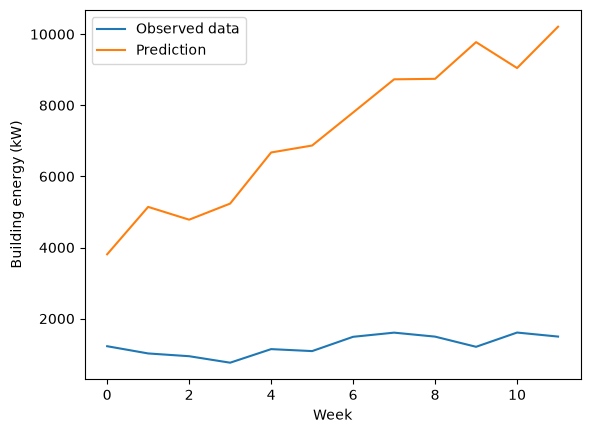

In [21]:
plt.plot(test.values, label = "Observed data")
plt.plot(predictions.flatten(), label = "Prediction")
plt.legend()
plt.xlabel("Week")
plt.ylabel("Building energy (kW)")